<a href="https://colab.research.google.com/github/rachana1707-S/Adaptive-MedRAG/blob/feature%2Frachana-retrieval/notebooks/01_retrieval.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [29]:
# Installing the libraries needed for my retrieval experiments
# huggingface_hub will help me download NFCorpus
# rank-bm25 will be used for the BM25 baseline

!pip -q install huggingface_hub pandas pyarrow numpy rank-bm25

In [30]:
# Importing the libraries that I will use in this notebook

import re
import time

from pathlib import Path

import numpy as np
import pandas as pd

from huggingface_hub import hf_hub_download
from rank_bm25 import BM25Okapi

In [31]:
# Creating folders to store the dataset and experiment results

DATA_DIR = Path("data/nfcorpus")
RESULTS_DIR = Path("results")

DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Folders created successfully!")

Folders created successfully!


In [32]:
# Downloading the documents, queries, and test labels
# from Hugging Face instead of the original BEIR server

corpus_path = hf_hub_download(
    repo_id="BeIR/nfcorpus",
    filename="corpus/corpus-00000-of-00001.parquet",
    repo_type="dataset"
)

queries_path = hf_hub_download(
    repo_id="BeIR/nfcorpus",
    filename="queries/queries-00000-of-00001.parquet",
    repo_type="dataset"
)

qrels_path = hf_hub_download(
    repo_id="BeIR/nfcorpus-qrels",
    filename="test.tsv",
    repo_type="dataset"
)

print("All NFCorpus files downloaded successfully!")

All NFCorpus files downloaded successfully!


In [33]:
# Loading the dataset files into pandas DataFrames

corpus_df = pd.read_parquet(corpus_path)
queries_df = pd.read_parquet(queries_path)
qrels_df = pd.read_csv(qrels_path, sep="\t")

# Checking the number of documents and queries

print("Total documents:", len(corpus_df))
print("Total queries:", len(queries_df))
print("Total relevance labels:", len(qrels_df))

Total documents: 3633
Total queries: 3237
Total relevance labels: 12334


In [34]:
# Looking at the column names before preprocessing the data

print("Corpus columns:", corpus_df.columns.tolist())
print("Query columns:", queries_df.columns.tolist())
print("Qrels columns:", qrels_df.columns.tolist())

# Displaying some documents and queries

display(corpus_df.head(3))
display(queries_df.head(3))
display(qrels_df.head(3))

Corpus columns: ['_id', 'title', 'text']
Query columns: ['_id', 'title', 'text']
Qrels columns: ['query-id', 'corpus-id', 'score']


,_id,title,text
0,MED-10,Statin Use and Breast Cancer Survival: A Natio...,"Recent studies have suggested that statins, an..."
1,MED-14,Statin use after diagnosis of breast cancer an...,BACKGROUND: Preclinical studies have shown tha...
2,MED-118,Alkylphenols in human milk and their relations...,The aims of this study were to determine the c...


,_id,title,text
0,PLAIN-3,,Breast Cancer Cells Feed on Cholesterol
1,PLAIN-4,,Using Diet to Treat Asthma and Eczema
2,PLAIN-5,,Treating Asthma With Plants vs. Pills


,query-id,corpus-id,score
0,PLAIN-2,MED-2427,2
1,PLAIN-2,MED-10,2
2,PLAIN-2,MED-2429,2


In [35]:
# Using document and query IDs to access the data easily

corpus = {
    str(row["_id"]): {
        "title": str(row["title"] or ""),
        "text": str(row["text"] or "")
    }
    for _, row in corpus_df.fillna("").iterrows()
}

queries = {
    str(row["_id"]): str(row["text"])
    for _, row in queries_df.iterrows()
}

print("Corpus size:", len(corpus))
print("Queries loaded:", len(queries))

Corpus size: 3633
Queries loaded: 3237


In [36]:
# Creating a tokenizer to split the text into words
# Converting everything to lowercase so matching is consistent

import re

def tokenize(text):
    return re.findall(r"\b\w+\b", text.lower())

In [37]:
# Getting all the document IDs from our corpus

doc_ids = list(corpus.keys())

# Combining the title and text of each document

doc_texts = []

for doc_id in doc_ids:
    title = corpus[doc_id]["title"]
    text = corpus[doc_id]["text"]

    combined_text = title + " " + text
    doc_texts.append(combined_text)

print("Total documents:", len(doc_texts))

Total documents: 3633


In [38]:
# Tokenizing all documents before building the BM25 index

tokenized_corpus = []

for text in doc_texts:
    tokens = tokenize(text)
    tokenized_corpus.append(tokens)

# Checking how the first document looks after tokenization

print("First 20 tokens:")
print(tokenized_corpus[0][:20])

First 20 tokens:
['statin', 'use', 'and', 'breast', 'cancer', 'survival', 'a', 'nationwide', 'cohort', 'study', 'from', 'finland', 'recent', 'studies', 'have', 'suggested', 'that', 'statins', 'an', 'established']


In [39]:
# Importing the BM25 library

from rank_bm25 import BM25Okapi

# Building the BM25 index using the tokenized documents

bm25 = BM25Okapi(tokenized_corpus)

print("BM25 model created successfully!")

BM25 model created successfully!


In [40]:
# This function searches the corpus using BM25
# It returns the top k documents for a given question

import numpy as np

def bm25_search(query, top_k=5):

    # Tokenizing the user's question
    query_tokens = tokenize(query)

    # Getting BM25 scores for all documents
    scores = bm25.get_scores(query_tokens)

    # Sorting documents by their scores
    top_indices = np.argsort(scores)[::-1][:top_k]

    results = []

    # Collecting the top documents and their scores
    for rank, idx in enumerate(top_indices, start=1):

        doc_id = doc_ids[idx]

        results.append({
            "doc_id": doc_id,
            "chunk_id": None,
            "score": float(scores[idx]),
            "rank": rank,
            "title": corpus[doc_id]["title"],
            "text": corpus[doc_id]["text"]
        })

    return results

In [41]:
# Testing our retrieval function with a medical question

question = "What are the health benefits of dietary fiber?"

results = bm25_search(question, top_k=5)

# Displaying the retrieved documents

for result in results:

    print("Rank:", result["rank"])
    print("Document ID:", result["doc_id"])
    print("BM25 Score:", round(result["score"], 4))
    print("Title:", result["title"])
    print("Text:", result["text"][:200])
    print("-" * 50)

Rank: 1
Document ID: MED-2291
BM25 Score: 22.3933
Title: Viscous versus nonviscous soluble fiber supplements: mechanisms and evidence for fiber-specific health benefits.
Text: PURPOSE: This review focuses on the health benefits of viscous versus nonviscous soluble fibers, why symptoms can occur with increased fiber consumption, and how to avoid symptoms to improve adherence
--------------------------------------------------
Rank: 2
Document ID: MED-1374
BM25 Score: 21.6928
Title: Definitions and potential health benefits of the Mediterranean diet: views from experts around the world
Text: The Mediterranean diet has been linked to a number of health benefits, including reduced mortality risk and lower incidence of cardiovascular disease. Definitions of the Mediterranean diet vary across
--------------------------------------------------
Rank: 3
Document ID: MED-973
BM25 Score: 21.2251
Title: What is a high fiber diet?
Text: There is no recognized definition of what constitutes a high fi

In [42]:
# Selecting a question from the official test set

test_query_id = str(qrels_df["query-id"].iloc[0])

question = queries[test_query_id]

print("Query ID:", test_query_id)
print("Question:", question)

# Retrieving the top 5 documents

results = bm25_search(question, top_k=5)

for result in results:
    print(
        "Rank:", result["rank"],
        "| Document:", result["doc_id"],
        "| Score:", round(result["score"], 4)
    )

Query ID: PLAIN-2
Question: Do Cholesterol Statin Drugs Cause Breast Cancer?
Rank: 1 | Document: MED-14 | Score: 21.3211
Rank: 2 | Document: MED-2429 | Score: 21.2539
Rank: 3 | Document: MED-10 | Score: 19.329
Rank: 4 | Document: MED-2428 | Score: 19.1221
Rank: 5 | Document: MED-1193 | Score: 18.4465


In [43]:
# Saving the retrieved results so we can inspect them later

import pandas as pd

sample_results_df = pd.DataFrame(results)

sample_results_df.to_csv(
    RESULTS_DIR / "bm25_sample_results.csv",
    index=False
)

print("Sample BM25 results saved!")

Sample BM25 results saved!


In [44]:
# Downloading sample results to save them in our repository

from google.colab import files

files.download("results/bm25_sample_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [45]:
# Checking the relevance labels from NFCorpus
# These labels show which documents are relevant to each query

print("Qrels columns:", qrels_df.columns.tolist())

print("Total relevance entries:", len(qrels_df))

print("Number of test queries:", qrels_df["query-id"].nunique())

display(qrels_df.head())

Qrels columns: ['query-id', 'corpus-id', 'score']
Total relevance entries: 12334
Number of test queries: 323


,query-id,corpus-id,score
0,PLAIN-2,MED-2427,2
1,PLAIN-2,MED-10,2
2,PLAIN-2,MED-2429,2
3,PLAIN-2,MED-2430,2
4,PLAIN-2,MED-2431,2


In [46]:
# Creating a dictionary to store relevant documents for each query
# We will use this to compare against the BM25 search results

qrels = {}

for _, row in qrels_df.iterrows():

    query_id = str(row["query-id"])
    doc_id = str(row["corpus-id"])
    relevance = int(row["score"])

    # Only keeping documents with positive relevance scores
    if relevance > 0:

        if query_id not in qrels:
            qrels[query_id] = {}

        qrels[query_id][doc_id] = relevance

print("Queries with relevant documents:", len(qrels))

Queries with relevant documents: 323


In [47]:
# Checking one query and its relevant documents

sample_query_id = list(qrels.keys())[0]

print("Query ID:", sample_query_id)
print("Question:", queries[sample_query_id])

print("\nRelevant documents:")
print(qrels[sample_query_id])

Query ID: PLAIN-2
Question: Do Cholesterol Statin Drugs Cause Breast Cancer?

Relevant documents:
{'MED-2427': 2, 'MED-10': 2, 'MED-2429': 2, 'MED-2430': 2, 'MED-2431': 2, 'MED-14': 2, 'MED-2432': 2, 'MED-2428': 1, 'MED-2440': 1, 'MED-2434': 1, 'MED-2435': 1, 'MED-2436': 1, 'MED-2437': 1, 'MED-2438': 1, 'MED-2439': 1, 'MED-3597': 1, 'MED-3598': 1, 'MED-3599': 1, 'MED-4556': 1, 'MED-4559': 1, 'MED-4560': 1, 'MED-4828': 1, 'MED-4829': 1, 'MED-4830': 1}


In [48]:
# Recall@k measures how many relevant documents we found
# out of all relevant documents for a query

def recall_at_k(retrieved_ids, relevant_docs, k):

    relevant_ids = set(relevant_docs.keys())

    if len(relevant_ids) == 0:
        return 0.0

    # Taking only the top k retrieved documents
    top_k_ids = set(retrieved_ids[:k])

    # Counting how many retrieved documents are relevant
    relevant_found = len(top_k_ids.intersection(relevant_ids))

    recall = relevant_found / len(relevant_ids)

    return recall

In [49]:
# nDCG measures the quality of the document ranking
# It gives more importance to relevant documents near the top

def ndcg_at_k(retrieved_ids, relevant_docs, k):

    # Calculating DCG for the documents returned by BM25
    dcg = 0.0

    for rank, doc_id in enumerate(retrieved_ids[:k]):

        relevance = relevant_docs.get(doc_id, 0)

        dcg += (2 ** relevance - 1) / np.log2(rank + 2)

    # Calculating the best possible ranking score
    ideal_scores = sorted(
        relevant_docs.values(),
        reverse=True
    )[:k]

    idcg = 0.0

    for rank, relevance in enumerate(ideal_scores):

        idcg += (2 ** relevance - 1) / np.log2(rank + 2)

    # Avoiding division by zero
    if idcg == 0:
        return 0.0

    return dcg / idcg

In [50]:
# Testing our evaluation functions with a small example
# We know the expected results, so this checks our calculations

sample_relevant = {
    "doc_A": 2,
    "doc_B": 1
}

sample_retrieved = [
    "doc_A",
    "doc_C",
    "doc_B"
]

print("Recall@2:", recall_at_k(
    sample_retrieved, sample_relevant, 2
))

print("Recall@3:", recall_at_k(
    sample_retrieved, sample_relevant, 3
))

print("nDCG@3:", round(ndcg_at_k(
    sample_retrieved, sample_relevant, 3
), 4))

assert recall_at_k(sample_retrieved, sample_relevant, 2) == 0.5
assert recall_at_k(sample_retrieved, sample_relevant, 3) == 1.0
assert 0 <= ndcg_at_k(sample_retrieved, sample_relevant, 3) <= 1

print("Metric checks passed!")

Recall@2: 0.5
Recall@3: 1.0
nDCG@3: 0.9639
Metric checks passed!


In [51]:
# Running BM25 on all NFCorpus test queries
# For each query, we calculate recall, nDCG, and search time

evaluation_results = []

for query_id, relevant_docs in qrels.items():

    if query_id not in queries:
        continue

    question = queries[query_id]

    # Measuring the time taken by BM25 search
    start_time = time.perf_counter()

    results = bm25_search(question, top_k=10)

    search_time = (time.perf_counter() - start_time) * 1000

    # Getting the document IDs returned by BM25
    retrieved_ids = [result["doc_id"] for result in results]

    # Storing the metrics for this query
    evaluation_results.append({
        "query_id": query_id,
        "recall_5": recall_at_k(
            retrieved_ids, relevant_docs, 5
        ),
        "recall_10": recall_at_k(
            retrieved_ids, relevant_docs, 10
        ),
        "ndcg_10": ndcg_at_k(
            retrieved_ids, relevant_docs, 10
        ),
        "search_time_ms": search_time
    })

evaluation_df = pd.DataFrame(evaluation_results)

print("Total queries evaluated:", len(evaluation_df))

display(evaluation_df.head())

Total queries evaluated: 323


,query_id,recall_5,recall_10,ndcg_10,search_time_ms
0,PLAIN-2,0.166667,0.333333,0.795267,14.642891
1,PLAIN-12,0.000000,0.000000,0.000000,24.158136
2,PLAIN-23,0.033333,0.044444,0.178186,47.245771
3,PLAIN-33,0.031250,0.031250,0.098987,33.685179
4,PLAIN-44,0.000000,0.000000,0.000000,31.731291


In [52]:
# Calculating the average retrieval performance
# across all the test queries

summary = evaluation_df[
    ["recall_5", "recall_10", "ndcg_10", "search_time_ms"]
].mean()

print("BM25 Baseline Evaluation")
print("------------------------")

print("Recall@5:", round(summary["recall_5"], 4))
print("Recall@10:", round(summary["recall_10"], 4))
print("nDCG@10:", round(summary["ndcg_10"], 4))
print("Average search time (ms):",
      round(summary["search_time_ms"], 4))

BM25 Baseline Evaluation
------------------------
Recall@5: 0.115
Recall@10: 0.1521
nDCG@10: 0.3071
Average search time (ms): 10.1906


In [53]:
# Saving the results for every test query
# We will use them later when comparing retrieval methods

from pathlib import Path

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

evaluation_df.to_csv(
    RESULTS_DIR / "bm25_per_query.csv",
    index=False
)

print("Per-query results saved!")

Per-query results saved!


In [54]:
# Saving the average BM25 metrics in a separate CSV file

summary_df = summary.reset_index()

summary_df.columns = ["metric", "value"]

summary_df.to_csv(
    RESULTS_DIR / "bm25_summary.csv",
    index=False
)

display(summary_df)

print("BM25 summary saved!")

,metric,value
0,recall_5,0.115050
1,recall_10,0.152143
2,ndcg_10,0.307062
3,search_time_ms,10.190562


BM25 summary saved!


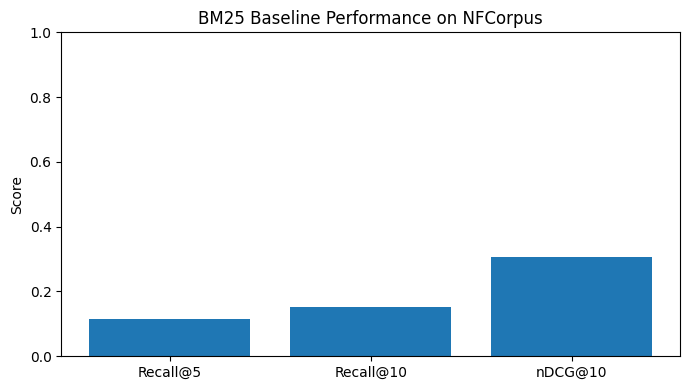

In [55]:
# Plotting the BM25 evaluation scores
# This graph will help us compare methods later

import matplotlib.pyplot as plt

metrics = ["Recall@5", "Recall@10", "nDCG@10"]

values = [
    summary["recall_5"],
    summary["recall_10"],
    summary["ndcg_10"]
]

plt.figure(figsize=(7, 4))

plt.bar(metrics, values)

plt.title("BM25 Baseline Performance on NFCorpus")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "bm25_metrics.png", dpi=150)

plt.show()

In [56]:
# Downloading my BM25 evaluation results
# These files will also be added to our GitHub repository

from google.colab import files

files.download("results/bm25_per_query.csv")
files.download("results/bm25_summary.csv")
files.download("results/bm25_metrics.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>